In [1]:
import pickle
from data_process import *
from mcar.simulate import *
from graphOUedge import GraphOUEdge

seed = 123
p = 0.15
gamma = 1.01
TICKERS = [str(i) for i in range (1,21)]
G = nx.erdos_renyi_graph(20, p, seed=seed)
G = nx.relabel_nodes(G, dict(enumerate(TICKERS)))
A = nx.to_numpy_array(G)

In [2]:
adj_sim = adj_to_line_graph(A, TICKERS)
adj_L_sim = adjacency_matrices(adj_sim[0], 1)
W_C_sim = edge_weight(adj_L_sim)
X_sim = GraphOUEdge([1], 34, 1, adj_L_sim, W_C_sim, gamma, 'test', scale=1, T=3)
X_sim.alpha_set(np.array([[5]+[1 for _ in range(33)]]))
X_sim.beta_set([[2]])
X_sim.Q_matrix()
data_sim = X_sim.simulate('CP', 10, seed=seed, rate=1)

In [3]:
edges = list(G.edges())
G_without_first = G.copy()
first_edge = edges[0]
G_without_first.remove_edge(*first_edge)
A_without_first = nx.to_numpy_array(G_without_first, nodelist=TICKERS)

G_without_last = G.copy()
last_edge = edges[-1]
G_without_last.remove_edge(*last_edge)
A_without_last = nx.to_numpy_array(G_without_last, nodelist=TICKERS)

In [4]:
model_pred(data=data_sim, test_size=400, adj_sim=adj_sim, forecast_step=1, P_Q_ratio=81, gamma=gamma, label='correct', scenario='test')
model_pred(data=data_sim, test_size=400, adj_sim=adj_to_line_graph(A_without_first, TICKERS), forecast_step=1, P_Q_ratio=81, gamma=gamma, label='missing_5', scenario='test')
model_pred(data=data_sim, test_size=400, adj_sim=adj_to_line_graph(A_without_last, TICKERS), forecast_step=1, P_Q_ratio=81, gamma=gamma, label='missing_1', scenario='test')

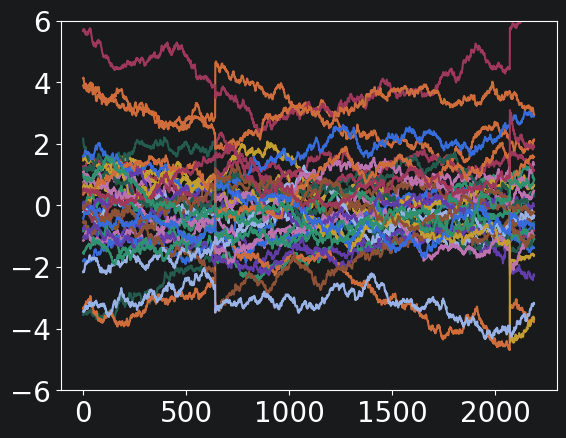

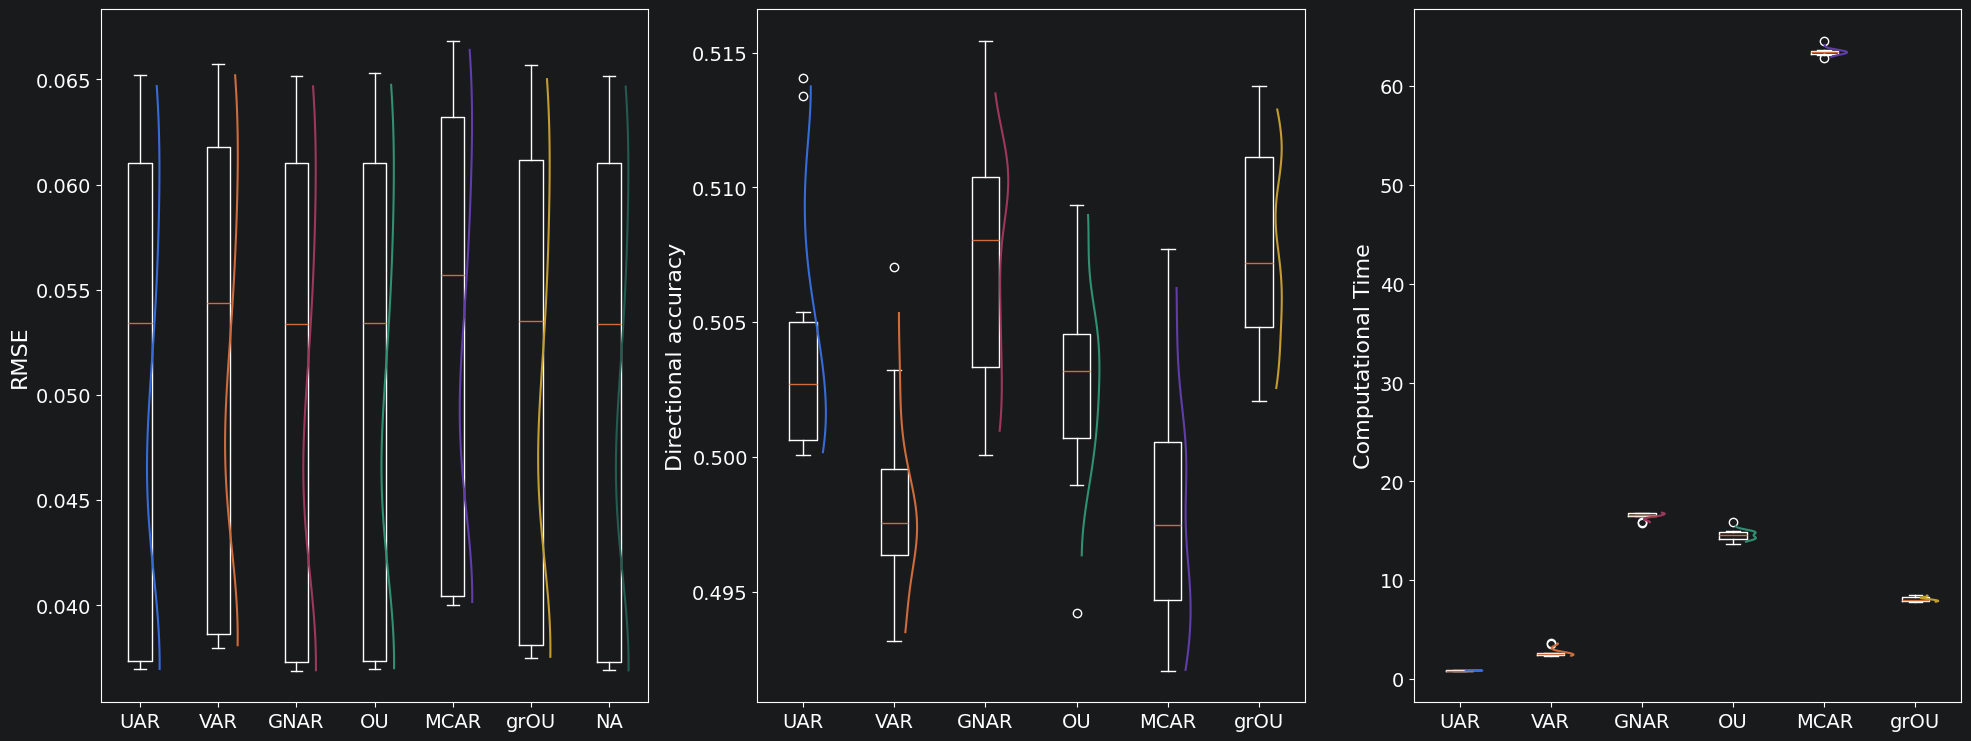

correct
                                UAR       VAR       GNAR         OU  \
RMSE_mean                  0.050504  0.051485   0.050474   0.050531   
RMSE_std                   0.011496  0.011200   0.011510   0.011498   
Directional_accuracy_mean  0.504404  0.498382   0.507346   0.502875   
Directional_accuracy_std   0.004929  0.003966   0.004602   0.004257   
Computational_time_mean    0.868148  2.709435  16.529057  14.607667   
Computational_time_std     0.016778  0.453195   0.343771   0.580808   

                                MCAR      grOU        NA  
RMSE_mean                   0.053009  0.050878  0.050473  
RMSE_std                    0.010942  0.011282  0.011509  
Directional_accuracy_mean   0.498169  0.507772       NaN  
Directional_accuracy_std    0.004949  0.003777       NaN  
Computational_time_mean    63.477806  8.073564       NaN  
Computational_time_std      0.438109  0.236772       NaN  


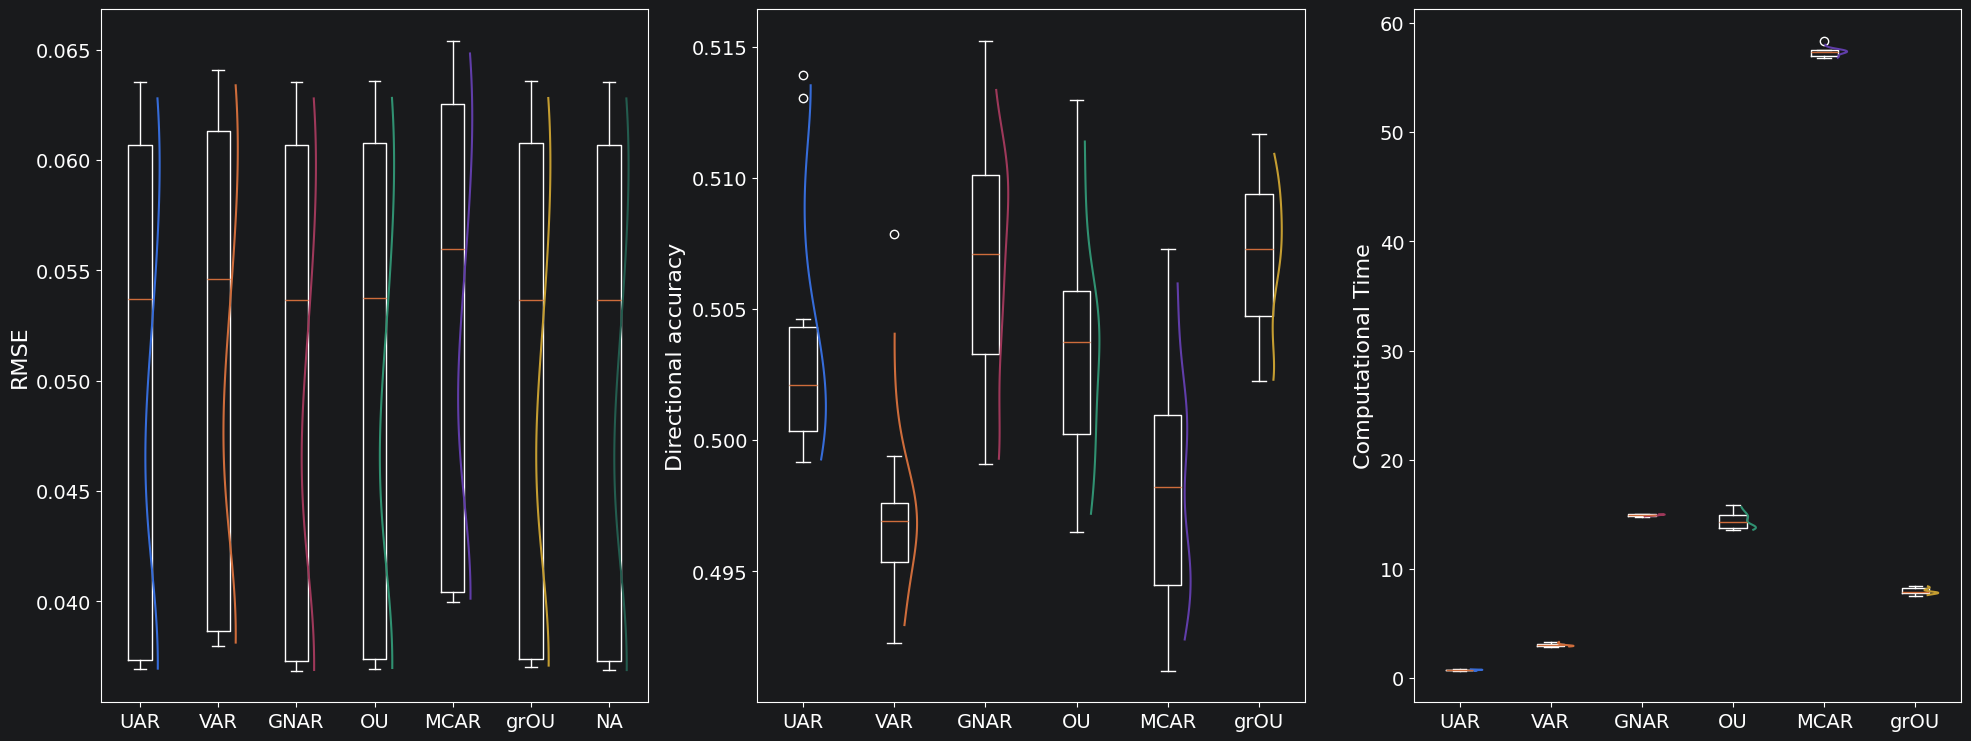

missing_5
                                UAR       VAR       GNAR         OU  \
RMSE_mean                  0.050163  0.051148   0.050132   0.050191   
RMSE_std                   0.011047  0.010747   0.011063   0.011052   
Directional_accuracy_mean  0.503894  0.497356   0.506674   0.503568   
Directional_accuracy_std   0.005067  0.004009   0.004938   0.004814   
Computational_time_mean    0.749992  3.057988  14.936574  14.453612   
Computational_time_std     0.044012  0.145016   0.072387   0.761434   

                                MCAR      grOU        NA  
RMSE_mean                   0.052680  0.050221  0.050129  
RMSE_std                    0.010524  0.011005  0.011062  
Directional_accuracy_mean   0.498417  0.506924       NaN  
Directional_accuracy_std    0.004830  0.003043       NaN  
Computational_time_mean    57.324635  7.981513       NaN  
Computational_time_std      0.434291  0.287879       NaN  


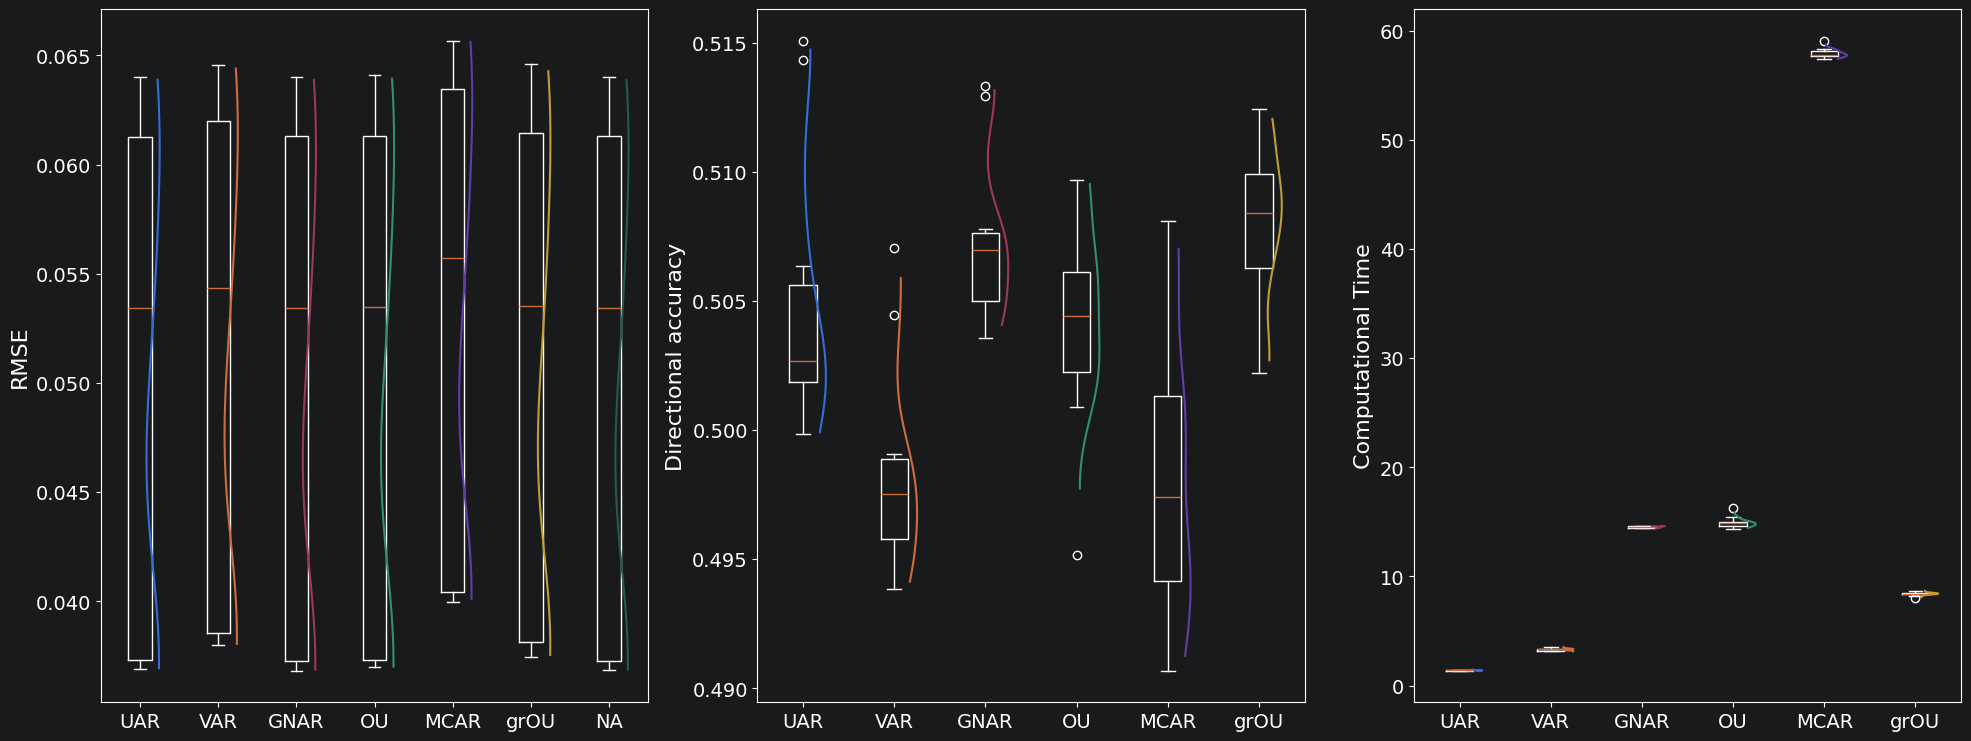

missing_1
                                UAR       VAR       GNAR         OU  \
RMSE_mean                  0.050407  0.051342   0.050381   0.050442   
RMSE_std                   0.011385  0.011104   0.011399   0.011381   
Directional_accuracy_mean  0.504826  0.498386   0.507364   0.504083   
Directional_accuracy_std   0.005228  0.004041   0.003155   0.004073   
Computational_time_mean    1.399916  3.316099  14.538685  14.960846   
Computational_time_std     0.034996  0.138969   0.066426   0.509826   

                                MCAR      grOU        NA  
RMSE_mean                   0.052918  0.050843  0.050376  
RMSE_std                    0.010829  0.011141  0.011398  
Directional_accuracy_mean   0.498189  0.507894       NaN  
Directional_accuracy_std    0.005502  0.003150       NaN  
Computational_time_mean    57.963190  8.414397       NaN  
Computational_time_std      0.468599  0.185581       NaN  


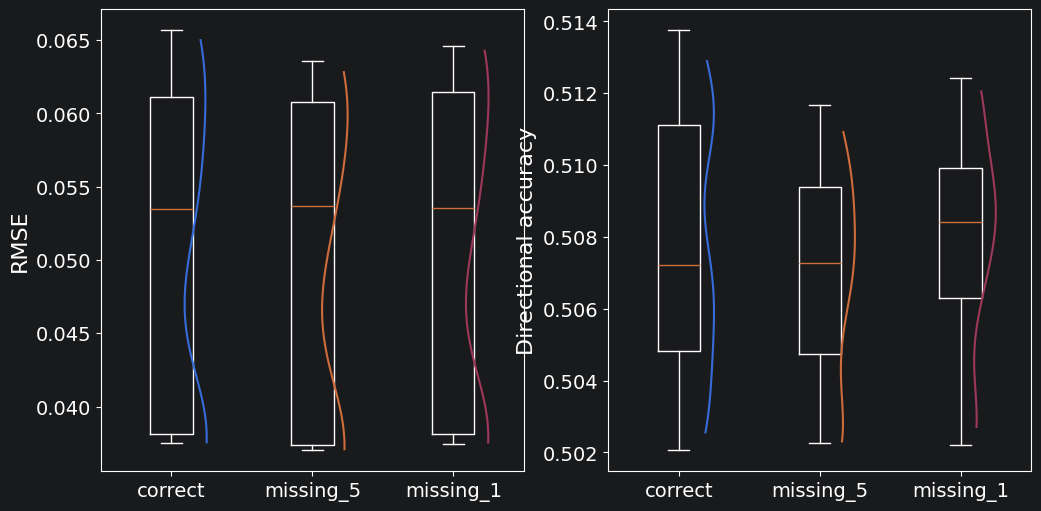

In [4]:
boxplot_(data_sim, 'test')